In [23]:
import matplotlib.pyplot as plt
import numpy as np


Ex 1

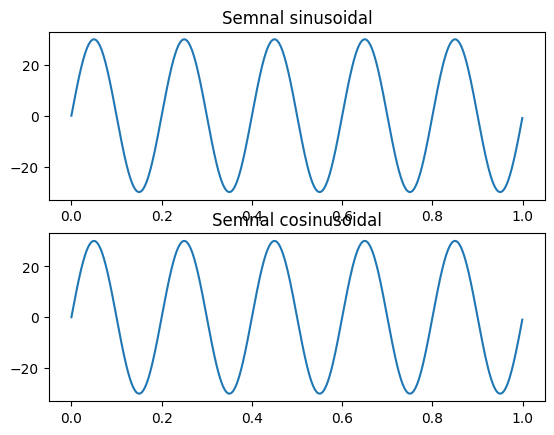

In [26]:
frecventa = 5
amplitudine = 30
faza_sin = 0

t = np.arange(0, 1, 0.001)

y_sin = amplitudine * np.sin(2 * np.pi * frecventa * t + faza_sin)

# am decalat faza de la cosinus să inceapă din același punct 
faza_cos = faza_sin - np.pi / 2
y_cos = amplitudine * np.cos(2 * np.pi * frecventa * t + faza_cos)

fig, axs = plt.subplots(2)

axs[0].plot(t, y_sin)
axs[0].set_title("Semnal sinusoidal")

axs[1].plot(t, y_cos)
axs[1].set_title("Semnal cosinusoidal")

plt.show()

Ex 2

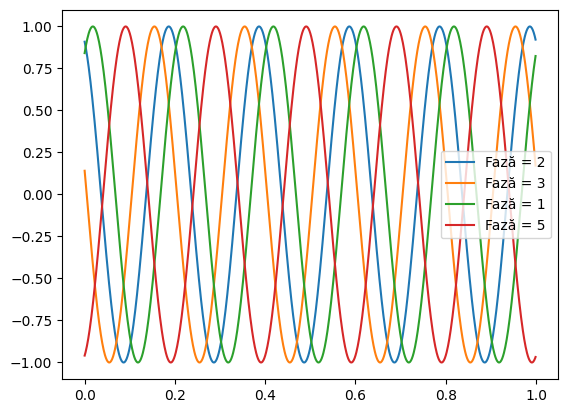

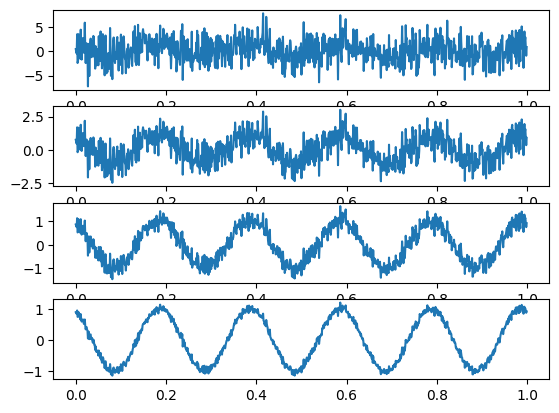

In [38]:
frecventa = 5
amplitudine = 1
faze = [2,3,1,5]

t = np.arange(0, 1, 0.001)

for faza in faze:
    x = amplitudine * np.sin(2 * np.pi * frecventa * t + faza)
    plt.plot(t, x, label=f'Fază = {faza}')
plt.legend()

list_SNR = [0.1, 1, 10, 100]

x = amplitudine * np.sin(2 * np.pi * frecventa * t + faze[0])
z = np.random.normal(loc=0.0, scale=1.0, size=len(t))

fig, axs = plt.subplots(len(list_SNR))

for i, snr in enumerate(list_SNR):
    gama = np.sqrt((np.linalg.norm(x) ** 2) / (snr * (np.linalg.norm(z) ** 2)))
    axs[i].plot(t, x + gama*z)
plt.show()


Ex 3

In [52]:
from scipy.io import wavfile
import sounddevice as sd

frecventa = 400
perioada_de_esantionare = 0.000025
timp_final = 1600 * perioada_de_esantionare

t = np.arange(0.0, timp_final, perioada_de_esantionare)
y = np.sin(2 * np.pi * frecventa * t + np.pi/3)

fs = int(1 / perioada_de_esantionare)

print("Redăm sunetul...")
sd.play(y, fs)
sd.wait()
print("Redare încheiată!")

nume = "semnal.wav"
y_int16 = (y * 32767).astype(np.int16)
wavfile.write(nume, fs, y_int16)
print(f"Fișierul '{nume}' a fost salvat cu succes pe disc!")

fs_citat, y_citat = wavfile.read(nume)
print(f"Verificare reușită! Rata citită: {fs_citat} Hz, Dimensiune date: {y_citat.shape}")

Redăm sunetul...
Redare încheiată!
Fișierul 'semnal.wav' a fost salvat cu succes pe disc!
Verificare reușită! Rata citită: 40000 Hz, Dimensiune date: (1600,)


Ex 4

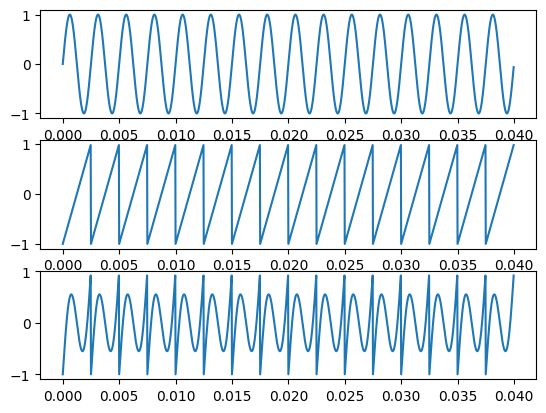

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth

frecventa = 400
perioada_de_esantionare = 0.000025
timp_final = 1600 * perioada_de_esantionare

t = np.arange(0, timp_final, perioada_de_esantionare)

semnale = []

semnale.append(np.sin(2 * np.pi * frecventa * t))
semnale.append(sawtooth(2 * np.pi * frecventa * t))

semnale.append(semnale[0] + semnale[1])

fig, axs = plt.subplots(3)

for i, semnal in enumerate(semnale):
    axs[i].plot(t, semnal)

plt.show()

Ex 5

In [63]:
import numpy as np
from scipy.io import wavfile
import sounddevice as sd

# Parametrii comuni
perioada_de_esantionare = 0.000025
fs = int(1 / perioada_de_esantionare)  # 40.000 Hz

# Durata totală dorită este de 5 secunde, împărțită la 2 semnale (câte 2.5 secunde fiecare)
durata_per_semnal = 2.5 
numar_esantioane = int(durata_per_semnal * fs)
t = np.arange(0.0, numar_esantioane * perioada_de_esantionare, perioada_de_esantionare)

# 1. Generarea primului semnal (400 Hz, timp de 2.5 secunde)
frecventa1 = 400
y1 = np.sin(2 * np.pi * frecventa1 * t + np.pi/3)

# 2. Generarea celui de-al doilea semnal (800 Hz, timp de 2.5 secunde)
frecventa2 = 800
y2 = np.sin(2 * np.pi * frecventa2 * t + np.pi/3)

# 3. Concatenarea (puse unul după celălalt)
y_concatenat = np.concatenate((y1, y2))

# 4. Redarea audio (va dura exact 5 secunde)
print("Redăm semnalul combinat timp de 5 secunde (400 Hz -> 800 Hz)...")
sd.play(y_concatenat, fs)
sd.wait()
print("Redare încheiată!")

# 5. Salvare ca fișier .wav
nume = "semnal_concatenat_5s.wav"
y_int16 = (y_concatenat * 32767).astype(np.int16)
wavfile.write(nume, fs, y_int16)
print(f"Fișierul '{nume}' a fost salvat cu succes pe disc!")

Redăm semnalul combinat timp de 5 secunde (400 Hz -> 800 Hz)...
Redare încheiată!
Fișierul 'semnal_concatenat_5s.wav' a fost salvat cu succes pe disc!
